# Variabilidade, intervalos e testes de hipótese

[▶ Abrir este notebook no Google Colab](https://colab.research.google.com/github/lalvim/disciplina_computacao_aplicada_humanidades_digitais/blob/main/unidade_05/02_incerteza_e_testes_de_hipotese.ipynb)

O Notebook 01 estimou uma diferença observada. Agora perguntamos que variação
esperaríamos se o procedimento de obtenção dos dados pudesse ser repetido.

## 1. Antes da inferência: de onde vêm os dados?

Variabilidade amostral é a variação de uma estatística entre amostras obtidas
pelo mesmo procedimento. Ela não é sinônimo de erro de medição, transformação,
lacuna de cobertura ou mudança histórica.

| Situação | O intervalo amostral resolve? | Razão |
|---|---|---|
| amostra probabilística de uma população definida | pode quantificar parte da incerteza | o desenho sustenta a generalização |
| corpus completo para a pergunta | geralmente não é a questão central | a diferença do corpus já é observada |
| coleção de conveniência | não corrige a seleção | a reamostragem herda a composição disponível |

**Nossa base não é amostra nem coleção de conveniência: é o corpus completo** de
discursos de posse presidencial de 1985 a 2023 — a segunda linha da tabela acima.
Não existe uma "população de discursos de posse possíveis" da qual esses 12 foram
sorteados; o bootstrap e o teste de permutação abaixo tratam os 12 valores
observados **como se** viessem de um procedimento repetível apenas para entender
o método. O resultado quantifica a variabilidade produzida pela regra de
reamostragem sobre exatamente estes 12 discursos — não incerteza sobre discursos
que não existem. Nenhuma conclusão histórica deve depender do valor de p abaixo.

In [ ]:
# @title Preparação do ambiente — execute esta célula no Google Colab
from pathlib import Path
import importlib.util
import os
import subprocess
import sys

URL_REPOSITORIO = 'https://github.com/lalvim/disciplina_computacao_aplicada_humanidades_digitais.git'
REPOSITORIO = Path(
    "/content/disciplina_computacao_aplicada_humanidades_digitais"
)
PASTA_UNIDADE = REPOSITORIO / 'unidade_05'

try:
    import google.colab  # type: ignore  # noqa: F401
    EM_COLAB = True
except ImportError:
    EM_COLAB = False

if EM_COLAB:
    if not (REPOSITORIO / ".git").exists():
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                "--branch",
                "main",
                URL_REPOSITORIO,
                str(REPOSITORIO),
            ],
            check=True,
        )

    PACOTES_COLAB = []
    ausentes = [
        especificacao
        for modulo, especificacao in PACOTES_COLAB
        if importlib.util.find_spec(modulo) is None
    ]
    if ausentes:
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", *ausentes],
            check=True,
        )

    os.chdir(PASTA_UNIDADE)
    print("Ambiente preparado em:", Path.cwd())
else:
    print("Ambiente local: nenhuma clonagem necessária.")

Ambiente local: nenhuma clonagem necessária.


Definido o alvo hipotético, podemos observar como uma estimativa varia entre
reamostras.

## 2. *Bootstrap* e distribuição da estimativa

![Uma amostra observada produz três reamostras com reposição, que convergem para uma distribuição bootstrap; a figura alerta que estrutura e vieses são herdados.](https://github.com/lalvim/disciplina_computacao_aplicada_humanidades_digitais/blob/main/unidade_05/imagens/02_fluxo_bootstrap.svg?raw=1)

Para cada repetição, sorteamos com reposição dentro de cada grupo e recalculamos
$\Delta_b=\bar{x}_{A,b}-\bar{x}_{B,b}$. A coleção dos valores aproxima a
variabilidade da estimativa sob o procedimento adotado. **Grupos e quantidade**,
como no Notebook 01: Pontas (1985, 1990, 1995, 2019, 2023; n=5) menos Centro
(1992, 1999, 2003, 2007, 2011, 2015, 2016; n=7), sobre `taxa_liberdade_mil`. Com
n=5 e n=7, o bootstrap tem poucos valores distintos possíveis — a distribuição
resultante é granulada, não contínua.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

docs = pd.read_csv("dados/derivados/documentos_processaveis.csv").sort_values("ano")
PONTAS = {1985, 1990, 1995, 2019, 2023}
docs["grupo"] = docs["ano"].map(lambda a: "Pontas" if a in PONTAS else "Centro")

a = docs.loc[docs.grupo.eq("Pontas"), "taxa_liberdade_mil"].to_numpy()
b = docs.loc[docs.grupo.eq("Centro"), "taxa_liberdade_mil"].to_numpy()
diferenca_observada = a.mean() - b.mean()

rng = np.random.default_rng(20260906)
B = 4000
diferencas_bootstrap = np.array([
    rng.choice(a, size=len(a), replace=True).mean()
    - rng.choice(b, size=len(b), replace=True).mean()
    for _ in range(B)
])
pd.Series(diferencas_bootstrap).describe(percentiles=[0.025, 0.5, 0.975]).round(4)

count    4000.0000
mean        2.4948
std         0.5111
min         1.0727
2.5%        1.6079
50%         2.4672
97.5%       3.5868
max         4.3748
dtype: float64

A distribuição não mostra 4.000 novos passados possíveis: mostra a variação
produzida pela regra de reamostragem sobre os dados observados.

## 3. Intervalo de confiança

Usaremos o intervalo percentil introdutório:

$$
IC_{95\%}=\left[Q_{0{,}025}(\Delta_b),Q_{0{,}975}(\Delta_b)\right].
$$

Em repetições do procedimento, cerca de 95% dos intervalos construídos desta
maneira cobririam o parâmetro-alvo sob as condições do método. Depois de
calculado, não dizemos que há 95% de probabilidade frequentista de o parâmetro
fixo estar neste intervalo. O intervalo tampouco contém 95% dos documentos — aqui,
com n=12 discursos no total, ele não contém 95% de 12 documentos, contém 95% dos
valores **recalculados** pela reamostragem.

,estimativa,limite inferior,limite superior,unidade
0,2.493,1.608,3.587,ocorrências de liberdade por 1.000 palavras


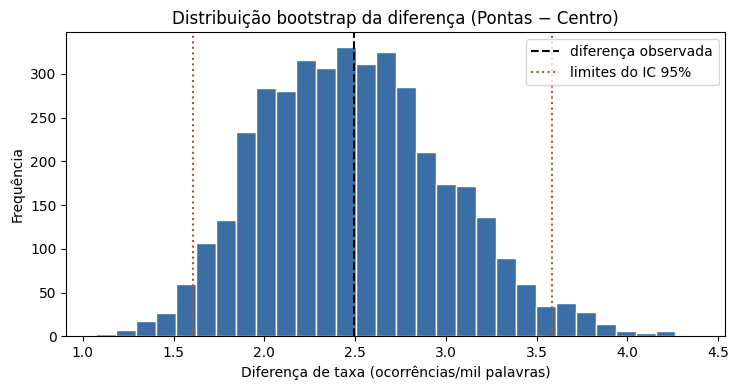

In [ ]:
limite_inferior, limite_superior = np.quantile(diferencas_bootstrap, [0.025, 0.975])
tabela_intervalo = pd.DataFrame([{
    "estimativa": diferenca_observada,
    "limite inferior": limite_inferior,
    "limite superior": limite_superior,
    "unidade": "ocorrências de liberdade por 1.000 palavras",
}])
display(tabela_intervalo.round(3))

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.hist(diferencas_bootstrap, bins=30, color="#3b6ea5", edgecolor="white")
ax.axvline(diferenca_observada, color="black", linestyle="--", label="diferença observada")
ax.axvline(limite_inferior, color="#a5573b", linestyle=":", label="limites do IC 95%")
ax.axvline(limite_superior, color="#a5573b", linestyle=":")
ax.set_title("Distribuição bootstrap da diferença (Pontas − Centro)")
ax.set_xlabel("Diferença de taxa (ocorrências/mil palavras)"); ax.set_ylabel("Frequência")
ax.legend()
plt.tight_layout(); plt.show()

O intervalo apresenta valores compatíveis com o procedimento de estimação. Um
teste responde a outra pergunta: quão incompatível é o resultado com um modelo
nulo especificado?

## 4. Hipótese nula e teste de permutação

A hipótese nula didática afirma que, sob permutação, os rótulos `Pontas` e
`Centro` são intercambiáveis. Mantemos valores e tamanhos dos grupos, embaralhamos
os rótulos e recalculamos a diferença. Com n=12 (5 e 7), existem `C(12,5) = 792`
divisões possíveis — o espaço de permutações é pequeno e enumerável; usamos
`M=5000` amostragens desse espaço com reposição, como o notebook original.

![Histograma de uma distribuição nula destaca as duas caudas e uma linha para o resultado observado, sem representar um limiar automático.](https://github.com/lalvim/disciplina_computacao_aplicada_humanidades_digitais/blob/main/unidade_05/imagens/02_distribuicao_nula.svg?raw=1)

Para $M$ permutações, uma estimativa bilateral com correção finita é:

$$
p=\frac{1+\sum_{m=1}^{M}\mathbf{1}(|T_m|\geq|T_{obs}|)}{M+1}.
$$

diferença observada     2.4930
valor de p bilateral    0.0018
dtype: float64

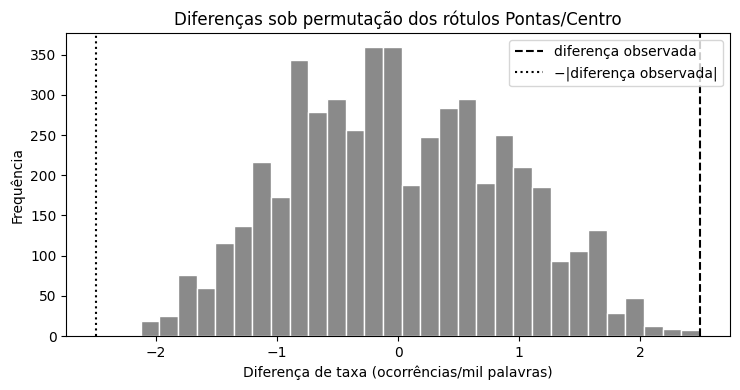

In [ ]:
rng = np.random.default_rng(20260906)
combinados = np.concatenate([a, b])
M = 5000
permutadas = []
for _ in range(M):
    embaralhados = rng.permutation(combinados)
    permutadas.append(embaralhados[:len(a)].mean() - embaralhados[len(a):].mean())
diferencas_nulas = np.array(permutadas)
valor_p = (1 + np.sum(np.abs(diferencas_nulas) >= abs(diferenca_observada))) / (M + 1)
display(pd.Series({"diferença observada": diferenca_observada,
                   "valor de p bilateral": valor_p}).round(4))

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.hist(diferencas_nulas, bins=30, color="#8a8a8a", edgecolor="white")
ax.axvline(diferenca_observada, color="black", linestyle="--", label="diferença observada")
ax.axvline(-diferenca_observada, color="black", linestyle=":", label="−|diferença observada|")
ax.set_title("Diferenças sob permutação dos rótulos Pontas/Centro")
ax.set_xlabel("Diferença de taxa (ocorrências/mil palavras)"); ax.set_ylabel("Frequência")
ax.legend()
plt.tight_layout(); plt.show()

## 5. Como interpretar o valor de *p*

![Estimativa, intervalo, valor de p e contexto aparecem em quatro caixas distintas; nenhuma substitui desenho, transparência, teoria ou leitura dos casos.](https://github.com/lalvim/disciplina_computacao_aplicada_humanidades_digitais/blob/main/unidade_05/imagens/02_mapa_interpretacao.svg?raw=1)

O valor de *p* indica quão extremos seriam resultados como o observado sob a
hipótese nula e o procedimento especificado. Ele **não** informa:

- a probabilidade de a hipótese nula ser verdadeira;
- a importância do resultado;
- a probabilidade de replicação;
- a ausência de viés;
- a qualidade da operacionalização.

Conclusões não devem depender apenas de atravessar `0,05`. Relate estimativa,
intervalo, medida de efeito, desenho, decisões analíticas e contexto. A ASA
(Wasserstein e Lazar, 2016) fundamenta essas cautelas.

## 6. Significância e relevância substantiva

Uma diferença muito pequena pode produzir valor de *p* baixo em grande amostra;
uma diferença importante pode permanecer imprecisa em amostra pequena. A
relevância depende da pergunta, da escala, das consequências e da literatura.

### U05-A03 — Atividade integrada — ficha inferencial

**Modalidade:** dupla. **Tempo:** 30
minutos.

1. declare população-alvo e procedimento de seleção;
2. informe estimativa, intervalo e tamanho de efeito;
3. formule a hipótese nula do teste;
4. interprete o valor de *p* sem decisão binária;
5. indique duas fontes de incerteza não representadas;
6. escreva uma conclusão substantiva limitada.

**Minha ficha**

| Item | Resposta |
|---|---|
| **População-alvo e seleção** | Não há população-alvo: os 12 discursos são o universo completo de posses presidenciais após a redemocratização de 1985 a 2023, não uma amostra selecionada de um conjunto maior. Bootstrap e permutação são usados aqui apenas como recurso metodológico para descrever a variabilidade da diferença observada sob reamostragem, não estimam incerteza sobre discursos que não existem. |
| **Estimativa, intervalo e efeito** | Diferença observada (Pontas − Centro) = 2,493 ocorrências/mil palavras. IC 95% bootstrap = [1,608; 3,587]. d padronizado (Notebook 01) = 2,930. |
| **Hipótese nula do teste** | Sob permutação, os rótulos `Pontas` e `Centro` são intercambiáveis entre os 12 discursos, isto é, a taxa de "liberdade" não depende de o discurso pertencer a uma ou outra metade da série temporal definida por H2. |
| **Valor de p e interpretação** | p = 0,0018 (bilateral, correção de +1). Sob a hipótese nula simulada, uma diferença tão extrema quanto a observada é rara nas 5.000 permutações. Isso não significa que a hipótese nula tem 0,18% de chance de ser verdadeira, nem que o achado é "importante": só descreve quão incomum é essa divisão específica entre 792 divisões possíveis de 12 itens em grupos de 5 e 7. |
| **Duas fontes de incerteza não representadas** | (1) A fronteira Pontas/Centro foi escolhida por mim, olhando o mesmo gráfico que gerou H2, é uma hipótese pós-hoc, não pré-registrada e outra divisão razoável dos 12 anos mudaria o resultado. (2) A contagem de "liberdade(s)" depende da segmentação por sentença e da regex `\bliberdades?\b`; nem bootstrap nem permutação capturam erro de medição ou de tokenização, só variabilidade de reamostragem. |
| **Conclusão substantiva limitada** | Nestes 12 discursos, a taxa de uso de "liberdade" é consistentemente maior nas pontas do período democrático (1985, 1990, 1995, 2019, 2023) do que no centro (1992–2016), e essa diferença não é um artefato de um único discurso influente (Notebook 01, sensibilidade sem Sarney). Isso descreve o corpus observado; não generaliza para discursos futuros nem explica a causa da diferença. |

**Situação em que eu não aplicaria inferência amostral**

Quando o "corpus" já é a população inteira relevante para a
pergunta, como no nosso caso, os 12 discursos de posse após a redemocratização de 1985 a 2023 não são uma
amostra de um universo maior de discursos de posse, são todos eles. Aplicar
bootstrap ou teste de permutação aqui é um exercício sobre variabilidade
de reamostragem, não uma estimativa de incerteza sobre uma população não observada.
Um valor de p pequeno não repara o fato de que a divisão Pontas/Centro foi definida
depois de ver o padrão (H2, Unidade 4), o mesmo tipo de problema apontado no guia
para "coleção de conveniência": a reamostragem herda qualquer viés já presente na
composição do corpus e na fronteira que eu escolhi traçar.

O eixo quantitativo está completo. No Notebook 03, a comparação muda de objeto:
representaremos documentos como termos e pesos antes de calcular semelhanças.